# 04 · Que ferramentas varrem os sensores?  🟡 *médio*

Cada programa de varredura monta seus pacotes **do seu jeito**: escolhe o TTL inicial, o tamanho da janela TCP,
as opções TCP e até o campo de identificação IP. Esses detalhes formam uma **impressão digital** (*fingerprint*).
Com ela, podemos agrupar origens pelo **tipo de ferramenta** — sem saber quem está por trás.

**Perguntas deste notebook**

1. Quais combinações de campos (assinaturas) são mais comuns?
2. Quanto do tráfego de cada sensor vem de **ZMap**, **Masscan**, botnets tipo **Mirai** e pilhas de **SO**?
3. Ferramentas diferentes têm **alcance** diferente (nº de sensores)?
4. Pelo TTL, **quão longe** estão as origens de cada sensor?
5. As impressões digitais de um mesmo IP são **consistentes**?

In [1]:
import os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# A pasta raiz da série (onde estão os .py). Funciona tanto na raiz quanto em solucoes/.
RAIZ = os.path.abspath("..") if os.path.basename(os.getcwd()) == "solucoes" else os.getcwd()
sys.path.insert(0, RAIZ)
import holoscope_io as hio
import holoscope_ana as ha
ha.estilo()

# >>> Para usar os DADOS REAIS, troque só esta linha pela pasta dos parquet <<<
PASTA = os.path.join(RAIZ, "dados_sinteticos")
if not os.path.isdir(PASTA):   # primeira vez: gera os dados fictícios (~20 s)
    import subprocess
    subprocess.run([sys.executable, os.path.join(RAIZ, "gerar_sintetico_real.py"), "--saida", PASTA], check=True)

In [2]:
df = hio.carregar_holoscope(PASTA, extras=("asn", "geo", "fingerprint"))
df["flags"] = hio.flags_texto(df["tcp_flags"])
syn = df[(df["transport_proto"] == "TCP") & df["flags"].isin(["S", "SEC"])].copy()   # só SYN de varredura
syn["ttl0"] = hio.ttl_inicial(syn["ttl"])
syn["saltos"] = hio.saltos(syn["ttl"])
SENS = sorted(df["sensor"].unique())
print(f"{len(syn):,} pacotes SYN de varredura ({len(syn)/len(df):.0%} do total)")

83 arquivos | 6 sensores (worker) | 2026-09-01 a 2026-09-14 | 2,024,894 pacotes | 144 MB na memória
origens reservadas/privadas descartadas: 35,000


1,691,282 pacotes SYN de varredura (84% do total)


## 1. Os campos da impressão digital

| campo | o que é | por que varia |
|---|---|---|
| `ttl` | contador decrementado a cada roteador | o **valor inicial** depende do SO/ferramenta (64 Linux, 128 Windows, 255 ferramentas "cruas") |
| `ip_id` | identificador do pacote IP | ZMap usa sempre **54321** |
| `window` | tamanho da janela TCP | Masscan usa **1024**; SOs usam valores grandes (64240, 29200…) |
| `tcp_options_ordered` | opções TCP, **na ordem** em que aparecem | Linux: `MSS,SACK,TS,NOP,WS`; Windows: `MSS,NOP,WS,NOP,NOP,SACK`; ferramentas costumam mandar poucas ou nenhuma |
| `mss`, `wscale`, `has_sack`, `has_ts` | valores das opções | idem |

**TTL inicial:** só vemos o TTL **depois** da viagem. Como os SOs usam valores padronizados (32, 64, 128, 255),
estimamos o inicial como o menor padrão ≥ TTL observado; a diferença é o nº de **saltos** (roteadores).

In [3]:
syn["ipid_zmap"] = syn["ip_id"] == 54321
assin = (syn.groupby(["ttl0", "window", "tcp_options_ordered", "ipid_zmap"], observed=True)
            .agg(pacotes=("src_ip", "size"), ips=("src_ip", "nunique"))
            .sort_values("pacotes", ascending=False))
assin["% pacotes"] = (assin["pacotes"] / assin["pacotes"].sum() * 100).round(1)
assin.head(12)

pacotes    ips  % pacotes
ttl0 window tcp_options_ordered     ipid_zmap                           
255  65535                          True        643569   5177       38.1
64   64240  MSS,SACK,TS,NOP,WS      False       447900  10159       26.5
255  1024   MSS                     False       392347   5775       23.2
128  64240  MSS,NOP,WS,NOP,NOP,SACK False        94079   4988        5.6
64   62883                          False           10     10        0.0
     38853                          False            9      9        0.0
     63839                          False            9      9        0.0
     14899                          False            9      9        0.0
     15457                          False            9      9        0.0
     60175                          False            9      9        0.0
     21533                          False            9      9        0.0
     47217                          False            9      9        0.0

**Leitura:** poucas assinaturas explicam quase todo o tráfego. A linha `ttl0=64`, sem opções, com janela
"aleatória" aparece **fragmentada** em muitas linhas (cada janela diferente vira uma linha) — sinal de que a
janela **não** é fixa naquela ferramenta.

## 2. Classificando por regras

Vamos transformar o conhecimento acima em **regras** (heurísticas da literatura, simplificadas):

| rótulo | regra |
|---|---|
| ZMap | `ip_id == 54321` |
| Masscan | janela 1024 **e** TTL inicial 255 |
| tipo Mirai | porta Telnet/IoT (23, 2323, 37215, 52869), **sem** opções TCP, TTL inicial 64 |
| pilha Linux | opções começam com `MSS,SACK,TS` |
| pilha Windows | opções `MSS,NOP,WS,NOP,NOP,SACK` |
| outro | o resto |

> ⚠️ São **heurísticas**. A assinatura "oficial" do Mirai, por exemplo, é o número de sequência TCP igual ao IP
> de destino — campo que **não temos** nos parquet. Por isso escrevemos "tipo Mirai". E qualquer ferramenta pode
> ser modificada para imitar outra.

In [4]:
def classificar(d):
    opts = d["tcp_options_ordered"].astype(str)
    regras = [
        (d["ip_id"] == 54321, "ZMap"),
        ((d["window"] == 1024) & (d["ttl0"] == 255), "Masscan"),
        (d["dst_port"].isin([23, 2323, 37215, 52869]) & (opts == "") & (d["ttl0"] == 64), "tipo Mirai"),
        (opts.str.startswith("MSS,SACK,TS"), "pilha Linux"),
        (opts == "MSS,NOP,WS,NOP,NOP,SACK", "pilha Windows"),
    ]
    return pd.Series(np.select([m for m, _ in regras], [r for _, r in regras], "outro"), index=d.index)

syn["ferramenta"] = classificar(syn)
FERR = ["ZMap", "Masscan", "tipo Mirai", "pilha Linux", "pilha Windows", "outro"]
CORF = {f: c for f, c in zip(FERR, ha.PALETA[:5] + [ha.CINZA])}
syn.groupby("ferramenta").agg(pacotes=("src_ip", "size"), ips=("src_ip", "nunique")).loc[FERR]

,pacotes,ips
ferramenta,,
ZMap,643587,5193
Masscan,392347,5775
tipo Mirai,105380,4959
pilha Linux,447900,10159
pilha Windows,94079,4988
outro,7989,3479


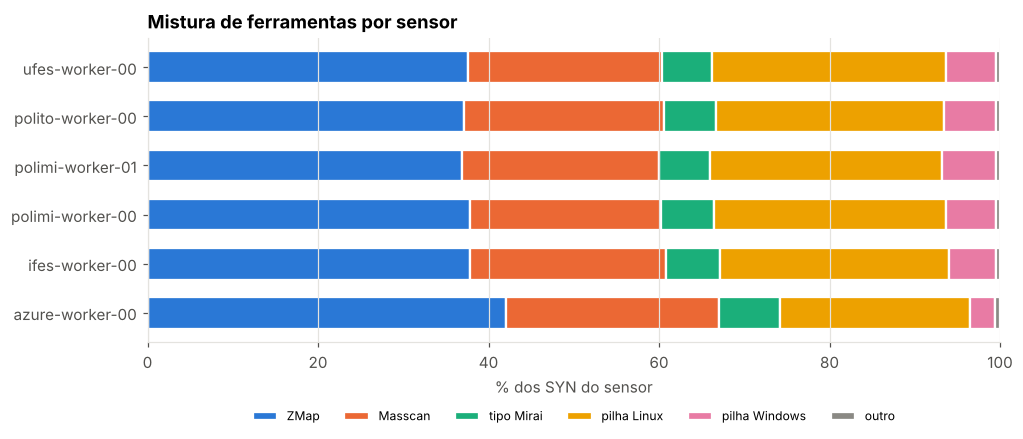

ferramenta,ZMap,Masscan,tipo Mirai,pilha Linux,pilha Windows,outro
sensor,,,,,,
azure-worker-00,42.0,25.0,7.2,22.4,2.9,0.5
ifes-worker-00,37.8,23.0,6.3,26.8,5.5,0.5
polimi-worker-00,37.8,22.4,6.2,27.2,5.9,0.5
polimi-worker-01,36.9,23.1,5.9,27.2,6.4,0.5
polito-worker-00,37.2,23.4,6.1,26.8,6.1,0.5
ufes-worker-00,37.6,22.8,5.9,27.4,5.9,0.4


In [5]:
mix = pd.crosstab(syn["sensor"], syn["ferramenta"], normalize="index")[FERR] * 100
fig, ax = plt.subplots(figsize=(10, 3.6))
esq = np.zeros(len(mix))
for f in FERR:
    ax.barh(mix.index, mix[f], left=esq, color=CORF[f], label=f, height=0.65, edgecolor="white", linewidth=1.5)
    esq += mix[f].values
ax.set_xlim(0, 100); ax.set_xlabel("% dos SYN do sensor"); ax.grid(axis="y", visible=False)
ax.set_title("Mistura de ferramentas por sensor")
ax.legend(ncol=6, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.18))
plt.show()
mix.round(1)

### ✏️ TODO 1 — Quanto é ZMap em cada sensor?

Guarde em `resp_1` uma `Series` (índice = sensor) com a fração (0 a 1) dos **IPs de origem** (não pacotes!)
de cada sensor que usaram ZMap pelo menos uma vez. É diferente da fração de pacotes da tabela acima?

<details><summary><b>Dica</b> (clique)</summary>

Para cada (sensor, IP), `any()` da coluna `ferramenta == "ZMap"`; depois média por sensor.

</details>

In [6]:
# SOLUÇÃO
por_ip = (syn["ferramenta"] == "ZMap").groupby([syn["sensor"], syn["src_ip"]], observed=True).any()
resp_1 = por_ip.groupby(level="sensor", observed=True).mean()
pd.DataFrame({"% IPs ZMap": resp_1 * 100, "% pacotes ZMap": mix["ZMap"]}).round(1)

,% IPs ZMap,% pacotes ZMap
sensor,,
azure-worker-00,24.0,42.0
ifes-worker-00,24.0,37.8
polimi-worker-00,24.1,37.8
polimi-worker-01,23.2,36.9
polito-worker-00,23.3,37.2
ufes-worker-00,24.0,37.6


In [7]:
# Verificação (não precisa mexer)
if resp_1 is None:
    print("⏳ TODO 1 ainda não resolvido")
else:
    assert set(resp_1.index) == set(SENS) and resp_1.between(0, 1).all()
    print("✅ TODO 1 ok")

✅ TODO 1 ok


## 3. Alcance: as ferramentas veem quantos sensores?

ZMap e Masscan foram feitos para varrer a internet **inteira** rapidamente. Botnets costumam escolher alvos
de forma mais aleatória e lenta. Isso deveria aparecer no **nº de sensores** em que cada IP é visto.

### ✏️ TODO 2 — Nº médio de sensores por IP, por ferramenta

Atribua a cada IP a sua ferramenta **mais frequente** e calcule, por ferramenta, o **nº médio de sensores**
em que esses IPs aparecem. Guarde em `resp_2` uma `Series` (índice = ferramenta). Faça um gráfico de barras.

<details><summary><b>Dica</b> (clique)</summary>

Ferramenta principal: `syn.groupby("src_ip")["ferramenta"].agg(lambda s: s.mode()[0])`.
Sensores por IP: `syn.groupby("src_ip")["sensor"].nunique()`.

</details>

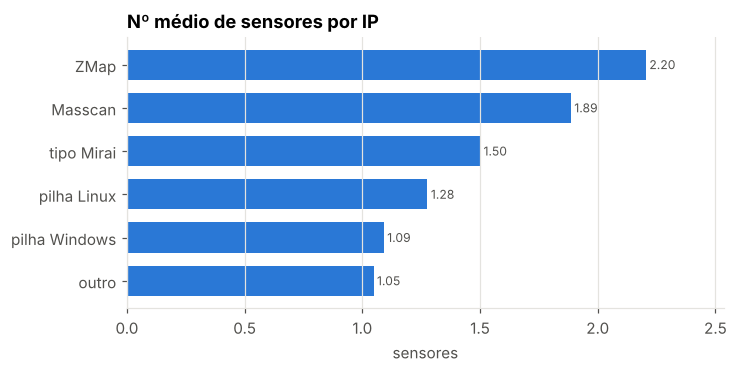

In [8]:
# SOLUÇÃO
principal = syn.groupby("src_ip")["ferramenta"].agg(lambda s: s.mode()[0])
n_sens = syn.groupby("src_ip")["sensor"].nunique()
resp_2 = n_sens.groupby(principal).mean().reindex(FERR)
fig, ax = plt.subplots(figsize=(7, 3.2))
ha.barras_h(resp_2.sort_values(ascending=False), ax=ax, fmt="{:.2f}",
            titulo="Nº médio de sensores por IP", xlabel="sensores")
plt.show()

In [9]:
# Verificação (não precisa mexer)
if resp_2 is None:
    print("⏳ TODO 2 ainda não resolvido")
else:
    assert resp_2.between(1, len(SENS)).all()
    print("✅ TODO 2 ok:", resp_2.round(2).to_dict())

✅ TODO 2 ok: {'ZMap': 2.2, 'Masscan': 1.89, 'tipo Mirai': 1.5, 'pilha Linux': 1.28, 'pilha Windows': 1.09, 'outro': 1.05}


## 4. Distância: TTL e saltos

O número de saltos depende do **caminho** entre a origem e o sensor. Origens geograficamente próximas tendem a
passar por menos roteadores. Vamos ver a distribuição de saltos por sensor:

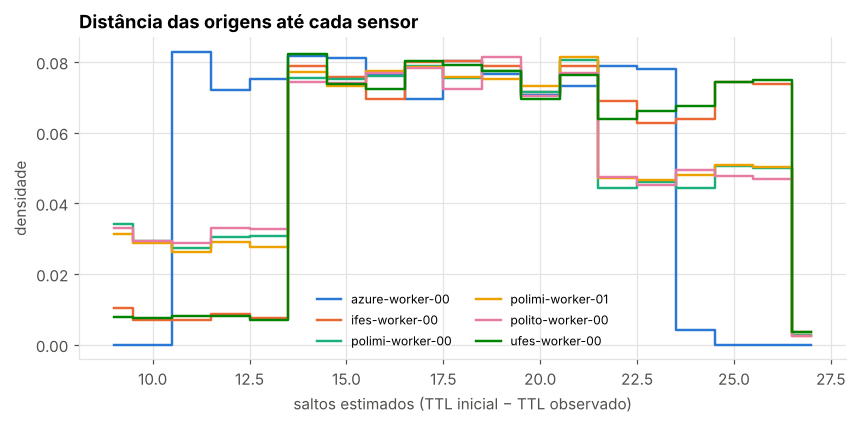

In [10]:
fig, ax = plt.subplots(figsize=(9, 3.8))
bins = np.arange(syn["saltos"].min(), min(syn["saltos"].max(), 40) + 2) - 0.5
COR = ha.cores(SENS)
for s in SENS:
    v = syn.loc[syn["sensor"] == s, "saltos"]
    h, _ = np.histogram(v, bins=bins, density=True)
    ax.step(bins[:-1] + 0.5, h, where="mid", color=COR[s], label=s, lw=1.6)
ax.set_xlabel("saltos estimados (TTL inicial − TTL observado)"); ax.set_ylabel("densidade")
ax.set_title("Distância das origens até cada sensor"); ax.legend(fontsize=8, ncol=2)
plt.show()

### ✏️ TODO 3 — Saltos por continente de origem × sensor

Monte em `resp_3` uma tabela **continente de origem × sensor** com a **mediana** de saltos e desenhe com
`ha.heatmap`. Origens da América do Sul ficam mais "perto" dos sensores brasileiros? E as europeias, dos italianos?

<details><summary><b>Dica</b> (clique)</summary>

`syn.pivot_table(index="continente", columns="sensor", values="saltos", aggfunc="median", observed=True)`.

</details>

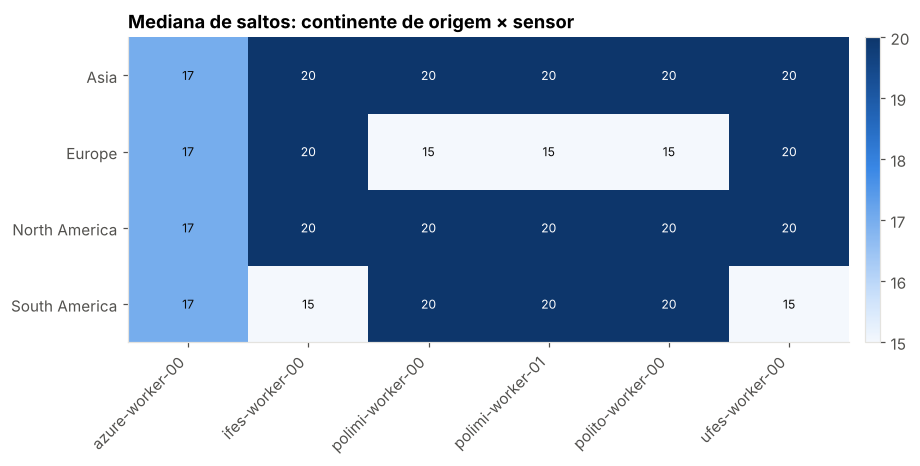

In [11]:
# SOLUÇÃO
resp_3 = syn.pivot_table(index="continente", columns="sensor", values="saltos", aggfunc="median", observed=True)
fig, ax = plt.subplots(figsize=(9, 3.6))
ha.heatmap(resp_3, ax=ax, fmt="{:.0f}", titulo="Mediana de saltos: continente de origem × sensor")
plt.show()

In [12]:
# Verificação (não precisa mexer)
if resp_3 is None:
    print("⏳ TODO 3 ainda não resolvido")
else:
    assert set(resp_3.columns) == set(SENS) and resp_3.shape[0] >= 4
    print("✅ TODO 3 ok")

✅ TODO 3 ok


> 💡 **Para que serve isso?** Se um IP aparece com saltos **muito** diferentes do esperado para o seu país, pode
> haver **falsificação de origem** (*spoofing*), um erro de geolocalização ou um roteamento incomum. E o TTL inicial
> ajuda a separar sistemas operacionais e ferramentas.

## 5. Consistência: um IP, uma impressão digital?

Uma máquina de verdade costuma usar **sempre** a mesma pilha/ferramenta e chegar a um sensor por um caminho estável.

In [13]:
cons = syn.groupby("src_ip").agg(ferramentas=("ferramenta", "nunique"), ttl0s=("ttl0", "nunique"),
                                 pacotes=("src_ip", "size"))
pd.DataFrame({"IPs": [len(cons), (cons["ferramentas"] > 1).sum(), (cons["ttl0s"] > 1).sum()]},
             index=["total", "com > 1 ferramenta", "com > 1 TTL inicial"])

,IPs
total,31058
com > 1 ferramenta,3494
com > 1 TTL inicial,0


### ✏️ TODO 4 — Investigar os inconsistentes

Pegue os IPs com **mais de uma ferramenta** e descubra **quais pares** de ferramentas aparecem juntos e com que
frequência. Guarde em `resp_4` uma `Series` com a contagem de cada combinação (ex.: `"outro + pilha Linux"`).
Que explicação você daria para a combinação mais comum? (Dica: olhe o que acontece com a regra "tipo Mirai"
quando a mesma máquina procura uma porta que não é Telnet.)

<details><summary><b>Dica</b> (clique)</summary>

`syn[syn["src_ip"].isin(ips)].groupby("src_ip")["ferramenta"].agg(lambda s: " + ".join(sorted(s.unique())))`
e depois `value_counts()`.

</details>

In [14]:
# SOLUÇÃO
ips = cons.index[cons["ferramentas"] > 1]
resp_4 = (syn[syn["src_ip"].isin(ips)].groupby("src_ip")["ferramenta"]
          .agg(lambda s: " + ".join(sorted(s.unique()))).value_counts())
resp_4.head(8)

ferramenta
outro + tipo Mirai           3478
Masscan + ZMap                  8
ZMap + pilha Linux              5
ZMap + pilha Windows            2
ZMap + outro + tipo Mirai       1
Name: count, dtype: int64

In [15]:
# Verificação (não precisa mexer)
if resp_4 is None:
    print("⏳ TODO 4 ainda não resolvido")
else:
    assert resp_4.sum() == (cons["ferramentas"] > 1).sum()
    print("✅ TODO 4 ok — combinação mais comum:", resp_4.index[0])

✅ TODO 4 ok — combinação mais comum: outro + tipo Mirai


## Resumo

* Poucos campos do cabeçalho (`ttl`, `ip_id`, `window`, opções TCP) formam **assinaturas** de ferramentas.
* Regras simples separam ZMap, Masscan, botnets tipo Mirai e pilhas de SO — mas são **heurísticas**.
* Ferramentas de varredura em massa alcançam **mais sensores** por IP.
* O nº de **saltos** reflete a distância origem → sensor e varia com a região.
* **Inconsistências** revelam limitações das regras (ou comportamento interessante).

## Desafios (sem solução)

1. **Agrupamento sem regras.** Use `sklearn.cluster.KMeans` (ou `DBSCAN`) sobre um vetor por IP
   (`ttl0`, `window` em log, presença de cada opção, `ip_id==54321`, pacotes/porta…). Os grupos batem com as regras?
2. **Sistema operacional dos pools.** No notebook 06 vamos achar redes /24 que dividem o trabalho. Elas usam
   a mesma ferramenta?
3. **Retransmissões.** Pilhas de SO retransmitem o SYN quando não há resposta (1 s, 3 s…). Use `flow_hash` e `ts`
   (extra `"fluxo"`) para medir os intervalos entre pacotes do mesmo fluxo. Que ferramentas retransmitem?
4. **Saltos por IP e sensor.** Para IPs vistos em vários sensores, os saltos são diferentes em cada sensor?
   Construa a matriz IP × sensor com a mediana de saltos e compare pares de sensores.